# WalkSAT — Proyecto Ciclo Hamiltoniano

Corremos **WalkSAT** (versión incremental) sobre la forma clausal que produce
Tseitin para encontrar un modelo del ciclo hamiltoniano.

- Cargamos la forma clausal de cada regla y de las 5 juntas desde `datos/tseitin.json`.
- WalkSAT incremental: guarda `ntrue` (literales verdaderos por cláusula) y `occ`
  (cláusulas donde aparece cada literal), así cada volteo es barato.
- Guardamos tiempos y resultados en `resultados/resultados_WalkSAT.csv`.
- Guardamos los modelos en `resultados/modelos_WalkSAT.json`.
- Visualizamos el ciclo con `H.visualizar_por_turnos`.

**Nota:** WalkSAT es **incompleto**: si devuelve `sin modelo`, no prueba que la
fórmula sea insatisfacible, solo que no encontró modelo con los intentos dados.

In [1]:
import os, sys, time, json, random
import pandas as pd
from logica import *
from problema import CicloHamiltoniano

sys.setrecursionlimit(10000)
os.makedirs('datos', exist_ok=True)
os.makedirs('resultados', exist_ok=True)

ciudades = ['Baq', 'Buc', 'Bog', 'Med', 'Per']
aristas  = [{0,1}, {1,2}, {2,3}, {3,4}, {2,4}, {0,2}, {1,4}]
coords   = {0:(0,3), 1:(3,3), 2:(1.5,1.8), 3:(0.3,0), 4:(2.7,0)}

H = CicloHamiltoniano(ciudades, aristas, coords)
print('Letras proposicionales Visita(c,t):', H.n * H.n)

SOLVER = 'WalkSAT'
resultados = {}
modelos = {}

Letras proposicionales Visita(c,t): 25


## Forma clausal (Tseitin)

WalkSAT trabaja con **formas clausales**: lista de cláusulas, cada una lista de
literales (`'-x'` = negación). Las leemos de `datos/tseitin.json` (dict
`nombre → lista de cláusulas`). Si no existe, la calculamos con `tseitin` y la
guardamos.

In [2]:
formulas = {f'Regla {k + 1}': H.reglas[k] for k in range(5)}
formulas['Reglas 1 a 5'] = Ytoria(H.reglas)
arboles = {nombre: inorder_to_tree(f) for nombre, f in formulas.items()}

if os.path.exists('datos/tseitin.json'):
    with open('datos/tseitin.json') as f:
        clausulas = json.load(f)
    print('Leído datos/tseitin.json')
else:
    clausulas = {nombre: tseitin(f) for nombre, f in formulas.items()}
    with open('datos/tseitin.json', 'w') as f:
        json.dump(clausulas, f)
    print('Calculado con tseitin y guardado en datos/tseitin.json')

pd.DataFrame([{'Fórmula': n, 'Nº cláusulas': len(C),
               'Nº letras': len({l.lstrip('-') for cl in C for l in cl})}
              for n, C in clausulas.items()])

Leído datos/tseitin.json


,Fórmula,Nº cláusulas,Nº letras
0,Regla 1,73,49
1,Regla 2,73,49
2,Regla 3,423,174
3,Regla 4,226,100
4,Regla 5,55,28
5,Reglas 1 a 5,858,319


## WalkSAT incremental

Para `max_tries` intentos: parte de una interpretación **aleatoria** y hace
hasta `max_flips` volteos. En cada volteo:

1. Escoge **al azar una cláusula insatisfecha** (si no hay, ya encontró modelo).
2. Para cada literal de esa cláusula calcula su `break_count`: cuántas cláusulas
   satisfechas se **romperían** si se voltea esa letra.
3. Si algún literal tiene `break_count = 0`, voltea ese. Si no, con probabilidad
   `p` (ruido) voltea uno al azar; con `1-p`, el de menor `break_count`.

**Versión incremental:** en vez de recalcular todas las cláusulas en cada
volteo, guarda para cada cláusula cuántos literales verdaderos tiene (`ntrue`)
y para cada literal en qué cláusulas aparece (`occ`). Al voltear solo se tocan
las cláusulas afectadas. Así 385 000 volteos se hacen en ~1 s en vez de ~190 s.

La semilla (`semilla`) hace que el resultado se pueda repetir.

In [3]:
def walksat(clausulas, max_flips=100000, max_tries=50, p=0.4, semilla=0, stats=None):
    '''WalkSAT sobre una forma clausal (lista de listas de literales).
    Devuelve un dict letra -> bool (modelo completo) o None.'''
    if stats is None:
        stats = {}
    stats['volteos'] = 0
    stats['intentos'] = 0
    azar = random.Random(semilla)

    letras = sorted({l.lstrip('-') for cl in clausulas for l in cl})
    indice = {x: i for i, x in enumerate(letras)}
    CL = [[(indice[l.lstrip('-')], not l.startswith('-')) for l in cl] for cl in clausulas]
    ocurre = {(v, s): [] for v in range(len(letras)) for s in (True, False)}
    for i, cl in enumerate(CL):
        for lit in cl:
            ocurre[lit].append(i)

    for _ in range(max_tries):
        stats['intentos'] += 1
        val = [azar.random() < 0.5 for _ in letras]
        ntrue = [sum(1 for (v, s) in cl if val[v] == s) for cl in CL]
        unsat = [i for i, n in enumerate(ntrue) if n == 0]
        donde = {c: k for k, c in enumerate(unsat)}

        for _ in range(max_flips):
            if not unsat:
                return {x: val[i] for x, i in indice.items()}
            c = unsat[azar.randrange(len(unsat))]
            cl = CL[c]
            bc = [sum(1 for j in ocurre[(v, val[v])] if ntrue[j] == 1) for (v, s) in cl]
            menor = min(bc)
            if menor == 0:
                k = azar.choice([k for k, b in enumerate(bc) if b == 0])
            elif azar.random() < p:
                k = azar.randrange(len(cl))
            else:
                k = azar.choice([k for k, b in enumerate(bc) if b == menor])
            v = cl[k][0]
            era, ahora = (v, val[v]), (v, not val[v])
            val[v] = not val[v]
            for j in ocurre[era]:
                ntrue[j] -= 1
                if ntrue[j] == 0:
                    donde[j] = len(unsat)
                    unsat.append(j)
            for j in ocurre[ahora]:
                if ntrue[j] == 0:
                    k2 = donde.pop(j)
                    ultima = unsat.pop()
                    if ultima != j:
                        unsat[k2] = ultima
                        donde[ultima] = k2
                ntrue[j] += 1
            stats['volteos'] += 1
    return None

## Correr WalkSAT sobre una regla

`correr_walksat` corre WalkSAT sobre la forma clausal de `nombre` y guarda una
fila en `resultados`. Para saber si el modelo es correcto, lo **verifica contra
la fórmula original** (`A.valor`), no solo contra las cláusulas: así se
comprueba también que Tseitin conserva los modelos. Las letras auxiliares de
Tseitin se ignoran al verificar y al dibujar.

In [4]:
def correr_walksat(nombre, max_flips=100000, max_tries=50, p=0.4, semilla=0):
    C = clausulas[nombre]
    A = arboles[nombre]
    stats = {}
    t0 = time.perf_counter()
    I = walksat(C, max_flips, max_tries, p, semilla, stats)
    seg = time.perf_counter() - t0
    verifica = None
    if I is not None:
        J = {l: I[l] for l in A.letras()}
        verifica = A.valor(J)
        modelos[nombre] = I
    resultados[nombre] = {'Solver': SOLVER, 'Regla': nombre,
                          'Resultado': 'modelo' if I is not None else 'sin modelo',
                          '¿Verifica?': verifica,
                          'Tiempo (s)': round(seg, 4),
                          'Nº cláusulas': len(C),
                          'Volteos': stats['volteos'],
                          'Intentos': stats['intentos']}
    r = resultados[nombre]
    print(f"{nombre:13s} | {r['Resultado']:10s} | ¿verifica? {str(verifica):5s} | {seg:8.4f} s | "
          f"{stats['volteos']:7d} volteos | {stats['intentos']:3d} intentos")
    return I

## Regla por regla

1. En cada posición hay al menos una ciudad.
2. Cada ciudad está en al menos una posición.
3. Cada ciudad está en a lo sumo una posición.
4. Transiciones válidas: posiciones consecutivas son ciudades conectadas.
5. Cierre del ciclo: la última posición conecta con la primera.

**Regla 1**

In [5]:
%%time
I = correr_walksat('Regla 1')

Regla 1       | modelo     | ¿verifica? True  |   0.0003 s |      27 volteos |   1 intentos
CPU times: user 471 μs, sys: 0 ns, total: 471 μs
Wall time: 473 μs


**Regla 2**

In [6]:
%%time
I = correr_walksat('Regla 2')

Regla 2       | modelo     | ¿verifica? True  |   0.0002 s |      15 volteos |   1 intentos
CPU times: user 327 μs, sys: 0 ns, total: 327 μs
Wall time: 329 μs


**Regla 3**

In [7]:
%%time
I = correr_walksat('Regla 3')

Regla 3       | modelo     | ¿verifica? True  |   0.0074 s |    2559 volteos |   1 intentos
CPU times: user 7.62 ms, sys: 0 ns, total: 7.62 ms
Wall time: 7.57 ms


**Regla 4**

In [8]:
%%time
I = correr_walksat('Regla 4')

Regla 4       | modelo     | ¿verifica? True  |   0.0037 s |    1407 volteos |   1 intentos
CPU times: user 3.87 ms, sys: 0 ns, total: 3.87 ms
Wall time: 3.87 ms


**Regla 5**

In [9]:
%%time
I = correr_walksat('Regla 5')

Regla 5       | modelo     | ¿verifica? True  |   0.0002 s |      21 volteos |   1 intentos
CPU times: user 38 μs, sys: 251 μs, total: 289 μs
Wall time: 291 μs


## Las cinco reglas juntas

Es el problema completo: la forma clausal de `Ytoria(H.reglas)` (858 cláusulas
y 319 letras, de las que solo 25 son `Visita(c,t)`). Cada intento tiene un tope
de `max_flips` volteos y se reinicia desde cero si no termina; WalkSAT puede
necesitar varios intentos.

In [10]:
%%time
I = correr_walksat('Reglas 1 a 5')

Reglas 1 a 5  | modelo     | ¿verifica? True  |   1.2184 s |  385277 volteos |   4 intentos
CPU times: user 1.22 s, sys: 0 ns, total: 1.22 s
Wall time: 1.22 s


## Visualización de la solución

WalkSAT asigna también las letras auxiliares de Tseitin; `_orden` las ignora y
solo usa las 25 letras `Visita(c,t)`. Dibujamos el modelo con el visualizador
por turnos (azul: camino; naranja: cierre del ciclo).

Recorrido: Buc -> Baq -> Bog -> Med -> Per -> Buc


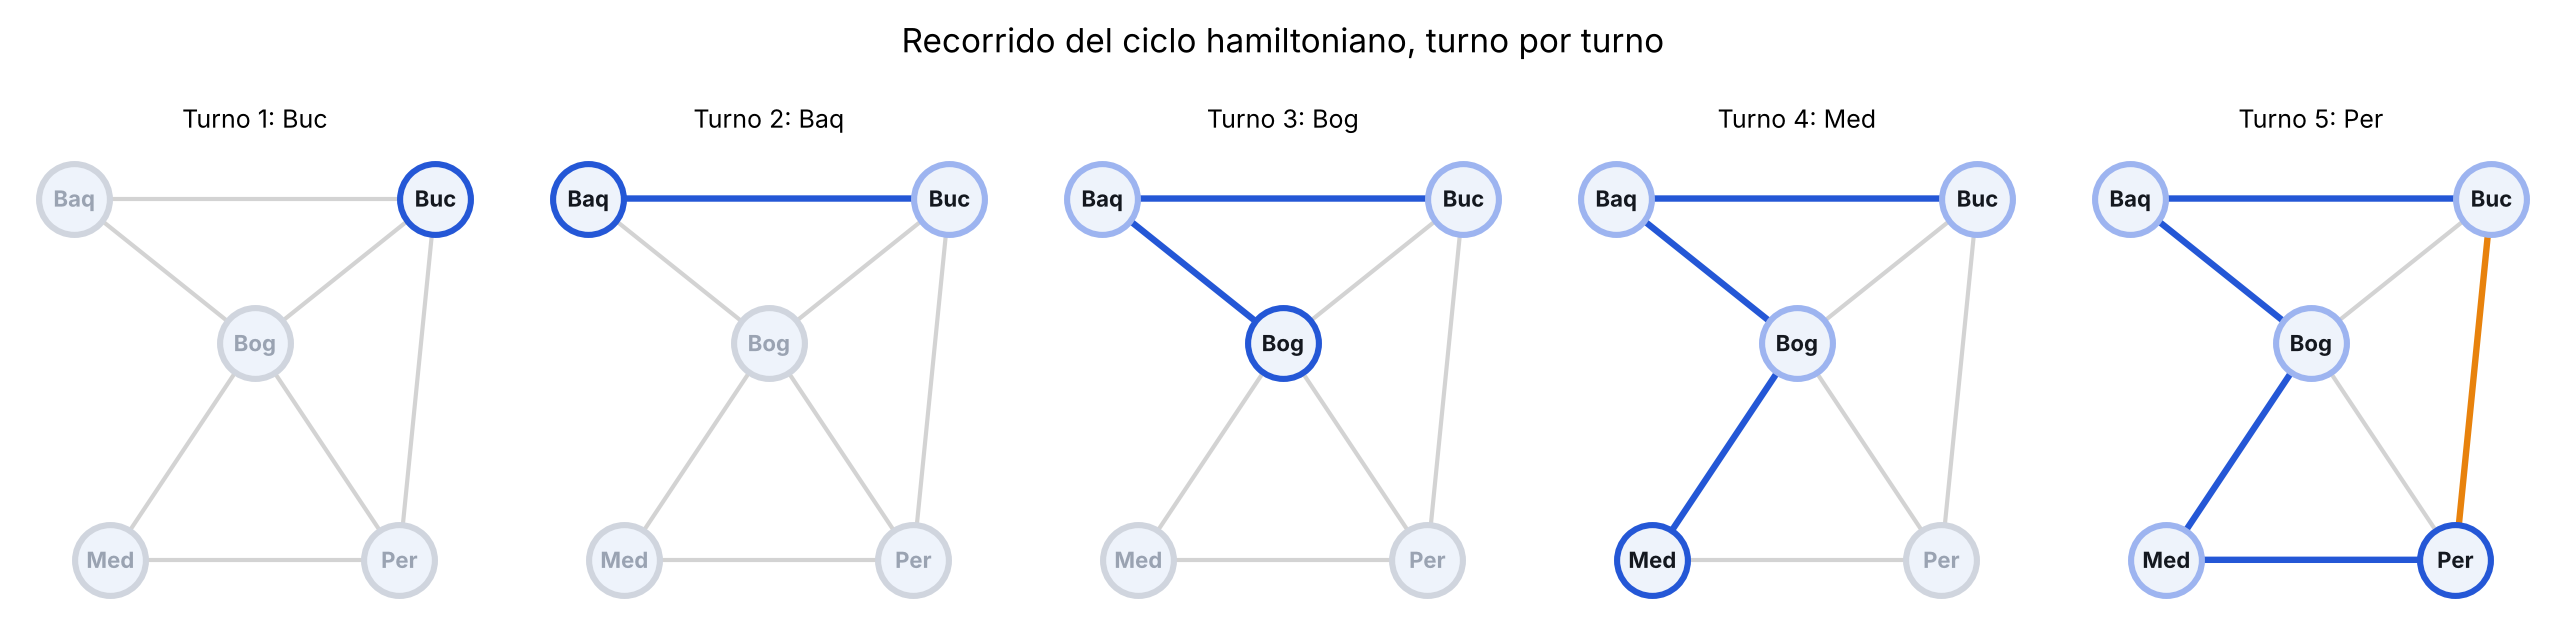

In [11]:
I_total = modelos.get('Reglas 1 a 5')
if I_total is not None:
    letras_originales = set(H.Visita.ravel([c, t])
                            for c in range(H.n) for t in range(H.n))
    I_filtrado = {k: v for k, v in I_total.items() if k in letras_originales}
    orden = H._orden(I_filtrado)
    if None not in orden:
        print('Recorrido:', ' -> '.join(H.ciudades[c] for c in orden),
              '->', H.ciudades[orden[0]])
        H.visualizar_por_turnos(I_filtrado)
    else:
        print('Modelo incompleto; no se puede dibujar')
else:
    print('WalkSAT no encontró modelo de las 5 reglas')

## Tabla resumen

Reúne las filas registradas y las guarda en `resultados/resultados_WalkSAT.csv`.

In [12]:
tabla = pd.DataFrame(list(resultados.values()))
tabla.to_csv('resultados/resultados_WalkSAT.csv', index=False)
tabla

,Solver,Regla,Resultado,¿Verifica?,Tiempo (s),Nº cláusulas,Volteos,Intentos
0,WalkSAT,Regla 1,modelo,True,0.0003,73,27,1
1,WalkSAT,Regla 2,modelo,True,0.0002,73,15,1
2,WalkSAT,Regla 3,modelo,True,0.0074,423,2559,1
3,WalkSAT,Regla 4,modelo,True,0.0037,226,1407,1
4,WalkSAT,Regla 5,modelo,True,0.0002,55,21,1
5,WalkSAT,Reglas 1 a 5,modelo,True,1.2184,858,385277,4


## Modelos a JSON

Guardamos `resultados/modelos_WalkSAT.json` con la misma estructura que los otros
notebooks. Incluye `extra` con número de cláusulas, volteos e intentos.

In [13]:
import json

modelos_WalkSAT = {'WalkSAT': {}}
for nombre, fila in resultados.items():
    modelos_WalkSAT['WalkSAT'][nombre] = {
        'resultado': fila['Resultado'],
        'verifica':  fila['¿Verifica?'],
        'tiempo_s':  fila['Tiempo (s)'],
        'modelo':    modelos.get(nombre),
        'extra': {
            'n_clausulas': fila['Nº cláusulas'],
            'volteos':     fila['Volteos'],
            'intentos':    fila['Intentos'],
        },
    }

with open('resultados/modelos_WalkSAT.json', 'w', encoding='utf-8') as f:
    json.dump(modelos_WalkSAT, f, ensure_ascii=False, indent=2)

print('Guardado resultados/modelos_WalkSAT.json')
for regla, datos in modelos_WalkSAT['WalkSAT'].items():
    print(f'  {regla:14s} → modelo: {datos["modelo"] is not None}')

Guardado resultados/modelos_WalkSAT.json
  Regla 1        → modelo: True
  Regla 2        → modelo: True
  Regla 3        → modelo: True
  Regla 4        → modelo: True
  Regla 5        → modelo: True
  Reglas 1 a 5   → modelo: True


## Conclusiones

- WalkSAT **incremental** encontró modelo de **todas** las reglas, incluida
  "Reglas 1 a 5", en ~1 s (385 277 volteos, 4 intentos).
- La clave es no recalcular las 858 cláusulas en cada volteo: guardando `ntrue`
  y `occ`, cada volteo solo toca las cláusulas afectadas. Eso da un factor de
  ~1000× frente a la versión ingenua (que tardaba 190 s y no encontraba modelo).
- **Contraste con DPLL** (≈0.02 s en `04_DPLL`): DPLL es más de 50× más rápido porque aprovecha la
  propagación unitaria, pero **ambos** encuentran modelo. La representación
  (Tseitin) no es el cuello de botella; el algoritmo sí.
- **Contraste con Tableaux anchura** (no termina) y **SATtabla** (≈90 s):
  WalkSAT y DPLL escalan, anchura no.

---